In [172]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit_aer import AerSimulator
import numpy as np
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

In [173]:
def Bernstein_Vazirani(Oracle, n):
    circuit= QuantumCircuit(n+1,n)
    for i in range(n):
        circuit.h(i)
    circuit.x(n)
    circuit.h(n)
    circuit.compose(Oracle, inplace= True)
    # circuit.barrier()
    for i in range(n):
        circuit.h(i)
    circuit.barrier()
    for i in range(n):
        circuit.measure(i,i)
    sim= AerSimulator()
    fake_backend= FakeManilaV2()
    noisy_simulator= AerSimulator.from_backend(fake_backend)
    print(fake_backend.target)
    transpiled_circuit= transpile(circuit, noisy_simulator, optimization_level=2)
    job= sim.run(transpiled_circuit, shots= 10024)
    results= job.result()
    print('QuantumCircuit:')
    # print(circuit)
    print('Result of the experiment:', results.get_counts())
    display(transpiled_circuit.draw('mpl'))

Target
Number of qubits: 5
Instructions:
	id
		(0,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000155066
		(1,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000392193
		(2,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000745816
		(3,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000212219
		(4,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000353872
	sx
		(0,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000155066
		(1,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000392193
		(2,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000745816
		(3,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000212219
		(4,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000353872
	reset
		(0,):
			Duration: 5.51467e-06 sec.
		(1,):
			Duration: 5.51467e-06 sec.
		(2,):
			Duration: 5.51467e-06 sec.
		(3,):
			Duration: 5.51467e-06 sec.
		(4,):
			Duration: 5.51467e-06 sec.
	x
		(0,):
			Duration: 3.55556e-08 sec.
			Error Rate: 0.000155066
		(1,):
			Duration: 3.55556e-08 sec

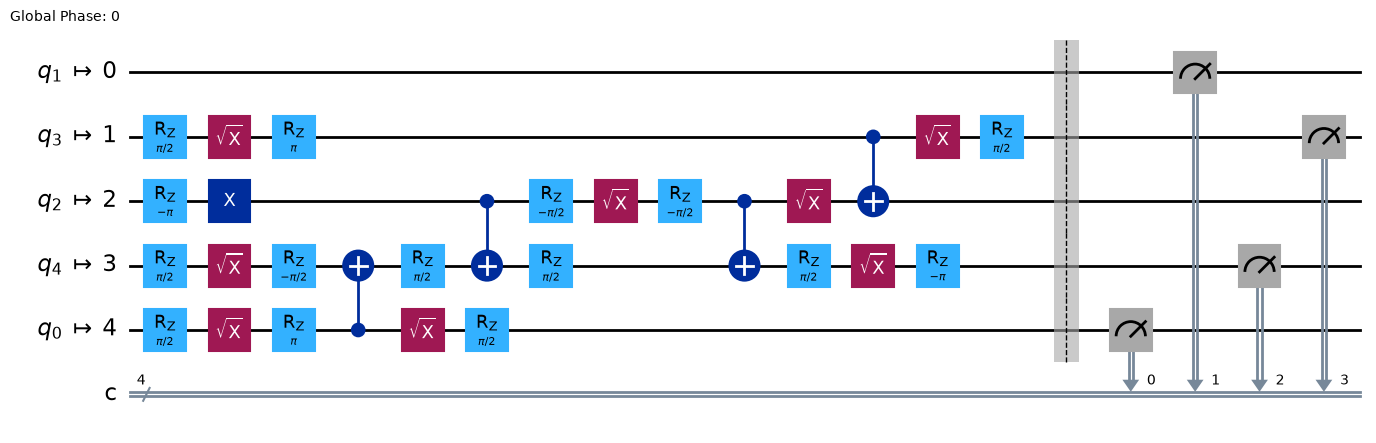

In [174]:
n=4
s='1101'
oracle= QuantumCircuit(n+1)
for i, bit in enumerate(reversed(s)):
    if bit=='1':
        oracle.cx(i,n)
Bernstein_Vazirani(oracle, n)
# oracle.draw('mpl')